<a href="https://colab.research.google.com/github/Cheponke/Transformation-Aware-Reliability-Modeling-for-Multi-Signal-Synthetic-Image-Attribution/blob/main/notebooks/05c_adoption_sweep.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# What if not every AI image is watermarked or signed?

The evaluation so far is the best case: every AI image carries the watermark and every image carries a C2PA credential. Under that assumption
the watermark alone has a slightly higher F1 than fusion (cross-validation, notebook 07), because it never has to decide a human image.
Real generators don't all watermark (open-source models usually don't) and few images carry credentials, so this asks:
**at what adoption level does fusion overtake the watermark alone?**

It recombines two saved runs of each model on the same test images from notebook 05: the watermarked run and the no-watermark ablation.
For an adoption rate p, each AI image is watermarked with probability p (its CNN score and watermark score come from the matching run),
the watermark detector and the fusion rule are re-applied, and this is repeated 20 times with different random draws.
C2PA adoption is varied the same way (0%, 50%, 100% of images signed).

**No GPU needed**: Runtime > Change runtime type > **CPU**. About 5 minutes.

## 1. Get the code

In [1]:
%cd /content
!rm -rf repo
!git clone https://github.com/Cheponke/Transformation-Aware-Reliability-Modeling-for-Multi-Signal-Synthetic-Image-Attribution.git repo
%cd /content/repo
!pip install -q -e ".[train]"

/content
Cloning into 'repo'...
remote: Enumerating objects: 510, done.
remote: Counting objects: 100% (274/274), done.
remote: Compressing objects: 100% (197/197), done.
remote: Total 510 (delta 166), reused 113 (delta 66), pack-reused 236 (from 1)
Receiving objects: 100% (510/510), 6.92 MiB | 13.20 MiB/s, done.
Resolving deltas: 100% (266/266), done.
/content/repo
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for attribution (pyproject.toml) ... done


## 2. Link the saved evaluation results on Google Drive

In [2]:
from google.colab import drive
import os
drive.mount("/content/drive")
D = "/content/drive/MyDrive/thesis-data"
!mkdir -p $D/evaluation && rm -rf outputs/evaluation && ln -s $D/evaluation outputs/evaluation
ARCHS = ["resnet50", "efficientnet_b0"]
missing = [f"outputs/evaluation/{a}{s}/per_image.csv" for a in ARCHS for s in ("", "_no_watermark")
           if not os.path.exists(f"outputs/evaluation/{a}{s}/per_image.csv")]
if missing:
    raise FileNotFoundError(f"missing {missing}: run notebook 05 sections 4 and 7 first")
print("found the watermarked and no-watermark runs for both models")

Mounted at /content/drive
found the watermarked and no-watermark runs for both models


## 3. Run the sweep

In [3]:
for arch in ARCHS:
    !python scripts/adoption_sweep.py --arch $arch --provenance-adoption 0 0.5 1

resnet50: 26928 image-condition pairs, 344 draws
  provenance 0 |          clean: fusion F1 >= watermark-only F1 at adoption 0;0.1;0.25;0.5;0.75;0.9
  provenance 0 |       jpeg_q90: fusion F1 >= watermark-only F1 at adoption 0;0.1;0.25;0.5;0.75;0.9
  provenance 0 |       jpeg_q70: fusion F1 >= watermark-only F1 at adoption 0;0.1;0.25;0.5;0.75;0.9
  provenance 0 |       jpeg_q50: fusion F1 >= watermark-only F1 at adoption 0;0.1;0.25;0.5;0.75
  provenance 0 |       jpeg_q30: fusion F1 >= watermark-only F1 at adoption 0;0.1;0.25;0.5;0.75
  provenance 0 |       webp_q80: fusion F1 >= watermark-only F1 at adoption 0;0.1;0.25;0.5;0.75;0.9
  provenance 0 |     resize_0.5: fusion F1 >= watermark-only F1 at adoption 0;0.1;0.25;0.5;0.75;0.9
  provenance 0 |    resize_0.25: fusion F1 >= watermark-only F1 at adoption 0;0.1;0.25;0.5;0.75;0.9;1
  provenance 0 |  recompress_x3: fusion F1 >= watermark-only F1 at adoption 0;0.1;0.25;0.5;0.75;0.9
  provenance 0.5 |          clean: fusion F1 >= watermark

## 4. Results
Each line is the mean F1 over 20 random draws (the shaded band is ± 1 sd). **Watermark adoption** on the x-axis is the share of AI images
carrying the watermark. The crossover table lists the adoption levels at which fusion's F1 is at least the watermark-only F1.
Look at coverage next to F1: the watermark alone never decides a human image.

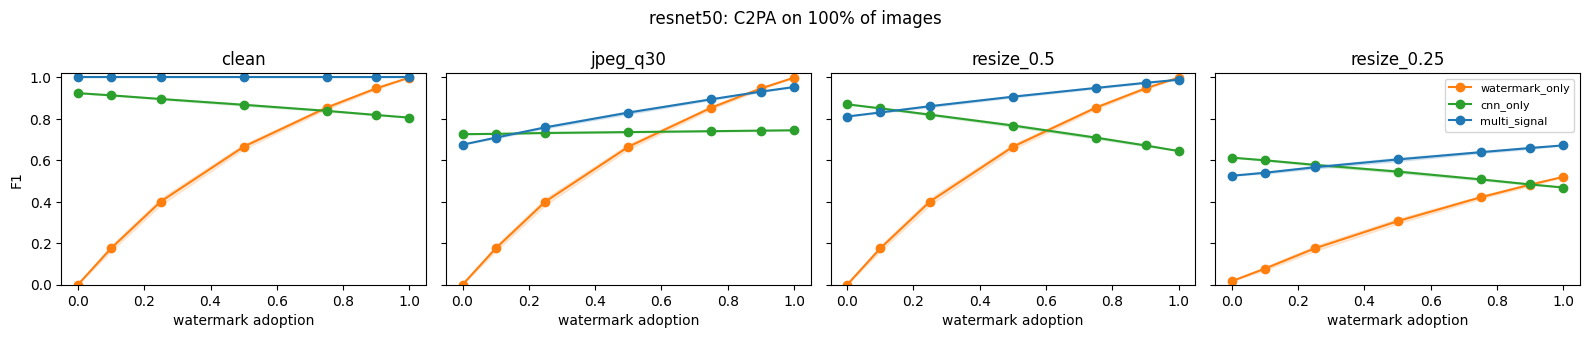

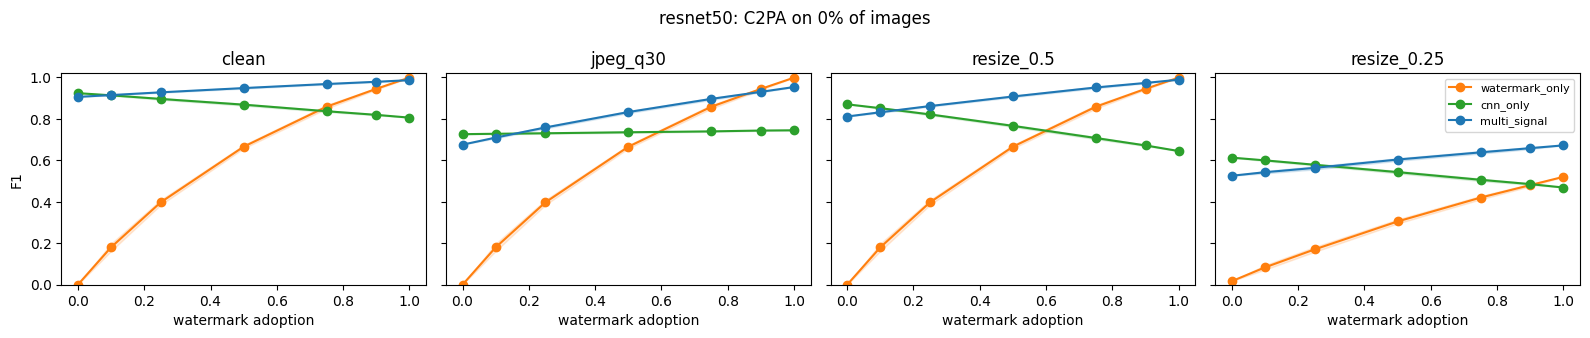

resnet50: watermark-adoption levels where fusion F1 >= watermark-only F1


,provenance_adoption,condition,levels_where_fusion_at_least_watermark
0,0.0,clean,0;0.1;0.25;0.5;0.75;0.9
1,0.0,jpeg_q90,0;0.1;0.25;0.5;0.75;0.9
2,0.0,jpeg_q70,0;0.1;0.25;0.5;0.75;0.9
3,0.0,jpeg_q50,0;0.1;0.25;0.5;0.75
4,0.0,jpeg_q30,0;0.1;0.25;0.5;0.75
5,0.0,webp_q80,0;0.1;0.25;0.5;0.75;0.9
6,0.0,resize_0.5,0;0.1;0.25;0.5;0.75;0.9
7,0.0,resize_0.25,0;0.1;0.25;0.5;0.75;0.9;1
8,0.0,recompress_x3,0;0.1;0.25;0.5;0.75;0.9
9,0.5,clean,0;0.1;0.25;0.5;0.75;0.9


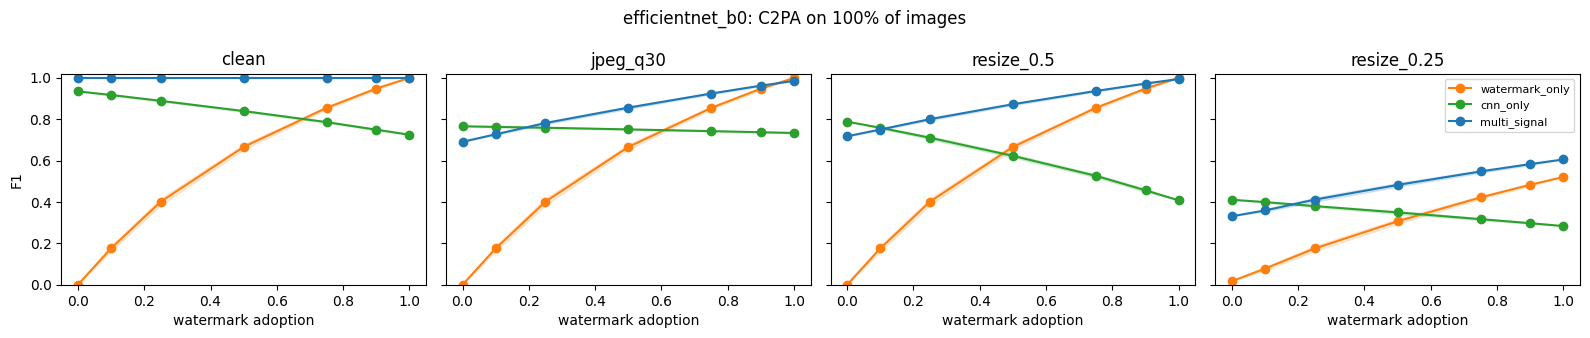

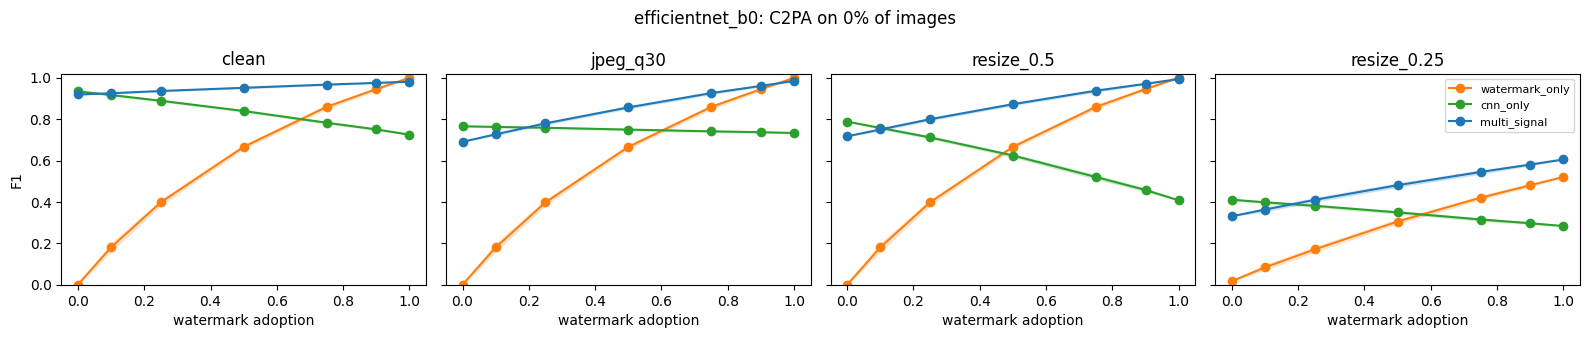

efficientnet_b0: watermark-adoption levels where fusion F1 >= watermark-only F1


,provenance_adoption,condition,levels_where_fusion_at_least_watermark
0,0.0,clean,0;0.1;0.25;0.5;0.75;0.9
1,0.0,jpeg_q90,0;0.1;0.25;0.5;0.75;0.9
2,0.0,jpeg_q70,0;0.1;0.25;0.5;0.75;0.9
3,0.0,jpeg_q50,0;0.1;0.25;0.5;0.75;0.9
4,0.0,jpeg_q30,0;0.1;0.25;0.5;0.75;0.9
5,0.0,webp_q80,0;0.1;0.25;0.5;0.75;0.9
6,0.0,resize_0.5,0;0.1;0.25;0.5;0.75;0.9
7,0.0,resize_0.25,0;0.1;0.25;0.5;0.75;0.9;1
8,0.0,recompress_x3,0;0.1;0.25;0.5;0.75;0.9
9,0.5,clean,0;0.1;0.25;0.5;0.75;0.9


In [4]:
import pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 220)
SHOW = ["clean", "jpeg_q30", "resize_0.5", "resize_0.25"]
STYLE = {"watermark_only": "tab:orange", "cnn_only": "tab:green", "multi_signal": "tab:blue"}
for arch in ARCHS:
    s = pd.read_csv(f"outputs/evaluation/adoption/{arch}/adoption_summary.csv")
    for prov in (1.0, 0.0):
        fig, axes = plt.subplots(1, len(SHOW), figsize=(16, 3.4), sharey=True)
        for ax, cond in zip(axes, SHOW):
            for system, color in STYLE.items():
                d = s[(s.condition == cond) & (s.system == system) & (s.provenance_adoption == prov)].sort_values("watermark_adoption")
                ax.plot(d.watermark_adoption, d.f1_mean, marker="o", color=color, label=system)
                ax.fill_between(d.watermark_adoption, d.f1_mean - d.f1_sd, d.f1_mean + d.f1_sd, color=color, alpha=0.15)
            ax.set_title(cond); ax.set_xlabel("watermark adoption"); ax.set_ylim(0, 1.02)
        axes[0].set_ylabel("F1"); axes[-1].legend(fontsize=8)
        fig.suptitle(f"{arch}: C2PA on {prov:.0%} of images"); plt.tight_layout(); plt.show()
    c = pd.read_csv(f"outputs/evaluation/adoption/{arch}/crossover.csv")
    print(f"{arch}: watermark-adoption levels where fusion F1 >= watermark-only F1")
    display(c[["provenance_adoption", "condition", "levels_where_fusion_at_least_watermark"]])

In [5]:
cols = ["watermark_adoption", "system", "f1_mean", "f1_sd", "coverage_mean", "recall_mean", "fpr_mean"]
for arch in ARCHS:
    s = pd.read_csv(f"outputs/evaluation/adoption/{arch}/adoption_summary.csv")
    t = s[(s.condition == "jpeg_q30") & (s.provenance_adoption == 1.0) & (s.system != "provenance_only")]
    print(f"{arch} | JPEG q30, C2PA on every image")
    display(t[cols].sort_values(["watermark_adoption", "system"]).round(4))

resnet50 | JPEG q30, C2PA on every image


,watermark_adoption,system,f1_mean,f1_sd,coverage_mean,recall_mean,fpr_mean
522,0.00,cnn_only,0.7264,0.0000,1.0000,0.6651,0.1654
523,0.00,multi_signal,0.6758,0.0000,0.8239,0.5593,0.0954
521,0.00,watermark_only,0.0000,0.0000,0.0000,0.0000,0.0000
558,0.10,cnn_only,0.7280,0.0012,1.0000,0.6674,0.1654
559,0.10,multi_signal,0.7095,0.0038,0.8334,0.6025,0.0954
557,0.10,watermark_only,0.1752,0.0134,0.0479,0.0960,0.0000
594,0.25,cnn_only,0.7322,0.0019,1.0000,0.6735,0.1654
595,0.25,multi_signal,0.7595,0.0049,0.8498,0.6709,0.0954
593,0.25,watermark_only,0.4012,0.0160,0.1253,0.2510,0.0000
630,0.50,cnn_only,0.7365,0.0022,1.0000,0.6797,0.1654


efficientnet_b0 | JPEG q30, C2PA on every image


,watermark_adoption,system,f1_mean,f1_sd,coverage_mean,recall_mean,fpr_mean
522,0.00,cnn_only,0.7656,0.0000,1.0000,0.6497,0.0474
523,0.00,multi_signal,0.6905,0.0000,0.8723,0.5432,0.0300
521,0.00,watermark_only,0.0000,0.0000,0.0000,0.0000,0.0000
558,0.10,cnn_only,0.7625,0.0019,1.0000,0.6455,0.0474
559,0.10,multi_signal,0.7267,0.0034,0.8827,0.5879,0.0300
557,0.10,watermark_only,0.1752,0.0134,0.0479,0.0960,0.0000
594,0.25,cnn_only,0.7585,0.0028,1.0000,0.6401,0.0474
595,0.25,multi_signal,0.7812,0.0055,0.8991,0.6603,0.0300
593,0.25,watermark_only,0.4012,0.0160,0.1253,0.2510,0.0000
630,0.50,cnn_only,0.7504,0.0026,1.0000,0.6291,0.0474


## 5. Save it
File > Save a copy in GitHub. The summaries are on Drive in `thesis-data/evaluation/adoption/` and are collected by notebook 06.